定义SVM模型

In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import time

class SVM_GD:
    def __init__(self, learning_rate=0.01, lambda_param=0.01, max_epochs=100, tol=1e-4, random_state=None):
        """
        初始化SVM模型
        
        参数:
        - learning_rate: 学习率 (默认: 0.01)
        - lambda_param: 正则化参数 (默认: 0.01)
        - max_epochs: 最大训练代数 (默认: 100)
        - tol: 收敛阈值 (默认: 1e-4)
        - random_state: 随机种子 (默认: None)
        """
        self.learning_rate = learning_rate
        self.lambda_param = lambda_param
        self.max_epochs = max_epochs
        self.tol = tol
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.train_loss_history = []
        self.train_acc_history = []
        self.test_loss_history = []
        self.test_acc_history = []
        
    def hinge_loss(self, y_true, y_pred):
        """计算Hinge Loss"""
        return np.maximum(0, 1 - y_true * y_pred).mean()
    
    def compute_loss(self, y_true, y_pred):
        """计算总损失（Hinge Loss + L2正则化）"""
        hinge_loss = self.hinge_loss(y_true, y_pred)
        regularization = (self.lambda_param / 2) * np.dot(self.weights, self.weights)
        return hinge_loss + regularization
    
    def fit(self, X_train, y_train, X_test=None, y_test=None, verbose=False, eval_interval=1):
        """
        训练SVM模型
        
        参数:
        - X_train: 训练特征矩阵 (n_samples, n_features)
        - y_train: 训练目标向量 (n_samples,)，取值应为{-1, 1}
        - X_test: 测试特征矩阵 (可选)
        - y_test: 测试目标向量 (可选)
        - verbose: 是否打印训练过程 (默认: False)
        - eval_interval: 评估间隔（每隔多少代评估一次） (默认: 1)
        """
        np.random.seed(self.random_state)
        n_samples, n_features = X_train.shape
        
        # 将标签转换为{-1, 1}
        y_train = np.where(y_train <= 0, -1, 1)
        if y_test is not None:
            y_test = np.where(y_test <= 0, -1, 1)
        
        # 初始化权重和偏置
        self.weights = np.random.randn(n_features)
        self.bias = 0
        
        # 清空历史记录
        self.train_loss_history = []
        self.train_acc_history = []
        self.test_loss_history = []
        self.test_acc_history = []
        
        for epoch in range(self.max_epochs):
            # 计算当前预测值
            linear_output = np.dot(X_train, self.weights) + self.bias
            y_pred = linear_output  # 对于SVM，直接使用线性输出
            
            # 计算梯度
            margins = y_train * y_pred
            dw = np.zeros(n_features)
            db = 0
            
            # 计算权重梯度
            for i, margin in enumerate(margins):
                if margin < 1:
                    dw += -y_train[i] * X_train[i]
                    db += -y_train[i]
            
            dw = dw / n_samples + self.lambda_param * self.weights
            db = db / n_samples
            
            # 更新参数
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            
            # 每隔eval_interval代评估一次
            if epoch % eval_interval == 0 or epoch == self.max_epochs - 1:
                # 训练集评估
                train_loss = self.compute_loss(y_train, y_pred)
                train_acc = accuracy_score(y_train, np.sign(y_pred))
                self.train_loss_history.append(train_loss)
                self.train_acc_history.append(train_acc)
                
                # 测试集评估（如果提供了测试集）
                if X_test is not None and y_test is not None:
                    test_pred = np.dot(X_test, self.weights) + self.bias
                    test_loss = self.compute_loss(y_test, test_pred)
                    test_acc = accuracy_score(y_test, np.sign(test_pred))
                    self.test_loss_history.append(test_loss)
                    self.test_acc_history.append(test_acc)
            
            # 打印训练过程
            if verbose and epoch % 10 == 0:
                print(f"Epoch {epoch}: Train Loss = {train_loss:.4f}, Train Acc = {train_acc:.4f}")
                if X_test is not None and y_test is not None:
                    print(f"       Test Loss = {test_loss:.4f}, Test Acc = {test_acc:.4f}")
            
            # 检查收敛
            if epoch > 0 and len(self.train_loss_history) > 1 and \
               abs(self.train_loss_history[-2] - self.train_loss_history[-1]) < self.tol:
                if verbose:
                    print(f"Converged at epoch {epoch}")
                break
                
        return self
    
    def predict(self, X):
        """预测类别"""
        linear_output = np.dot(X, self.weights) + self.bias
        return np.sign(linear_output)
    
    def score(self, X, y):
        """计算准确率"""
        y_pred = self.predict(X)
        y = np.where(y <= 0, -1, 1)  # 转换标签为{-1, 1}
        return accuracy_score(y, y_pred)


加载数据

In [147]:
def load_data(X_path, y_path):
    """加载数据"""
    X = pd.read_csv(X_path)
    y = pd.read_csv(y_path)
    
    # 确保X和y的行数匹配
    assert len(X) == len(y), "X和y的行数不匹配"
    
    # 提取特征和目标值
    X_values = X.values
    y_values = y.values.ravel()
    
    return X_values, y_values

可视化结果

In [148]:
def plot_learning_curves(train_loss, train_acc, test_loss=None, test_acc=None, 
                         eval_interval=1, title="Learning Curves"):
    """绘制学习曲线（损失和准确率）"""
    epochs = np.arange(0, len(train_loss) * eval_interval, eval_interval)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # 绘制训练损失曲线
    ax1.plot(epochs, train_loss, 'o-', label='Train Loss', color='tab:blue', markersize=5)
    if test_loss is not None:
        ax1.plot(epochs, test_loss, 'o-', label='Test Loss', color='tab:red', markersize=5)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Training & Test Loss')
    ax1.legend()
    ax1.grid(True)
    
    # 绘制准确率曲线
    ax2.plot(epochs, train_acc, 'o-', label='Train Accuracy', color='tab:orange', markersize=5)
    if test_acc is not None:
        ax2.plot(epochs, test_acc, 'o-', label='Test Accuracy', color='tab:green', markersize=5)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Training & Test Accuracy')
    ax2.legend()
    ax2.grid(True)
    
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

评估模型

In [149]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    """评估模型并绘制结果"""
    # 训练集评估
    train_acc = model.score(X_train, y_train)
    print(f"\nFinal Training Accuracy: {train_acc:.4f}")
    
    # 测试集评估
    test_acc = model.score(X_test, y_test)
    print(f"Final Test Accuracy: {test_acc:.4f}")
    
    # 绘制学习曲线
    plot_learning_curves(
        model.train_loss_history, 
        model.train_acc_history,
        model.test_loss_history,
        model.test_acc_history,
        eval_interval=1,
        title="SVM Training and Test Learning Curves"
    )
    
    return train_acc, test_acc

进行训练和预测


Training SVM with learning rate: 5e-05, lambda: 0.001
Training time(s): 2.2140204906463623

Final Training Accuracy: 0.8842
Final Test Accuracy: 0.8889


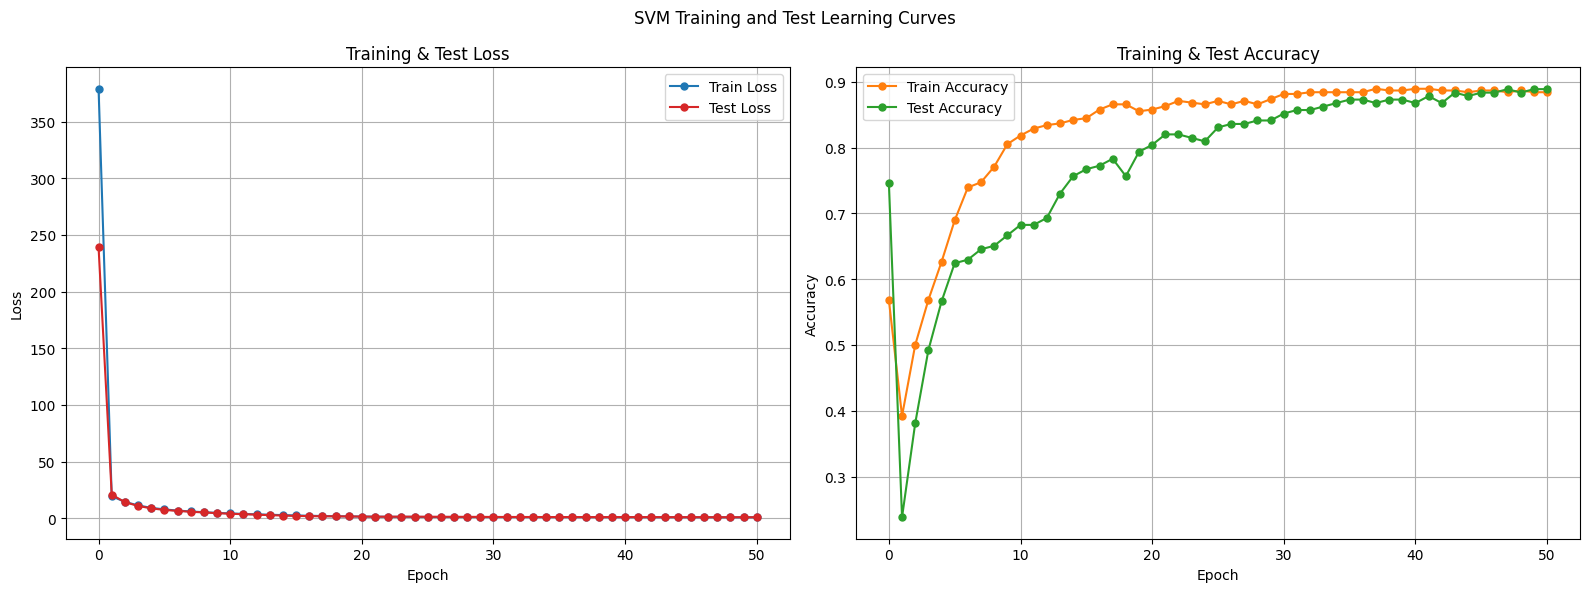


Final Results:
Learning Rate: 5e-05
Lambda: 0.001
Final Training Accuracy: 0.8842
Final Test Accuracy: 0.8889
Final Training Loss: 0.8193
Final Test Loss: 0.8627


In [150]:
def main():
    # 加载数据
    x_train, y_train = load_data('data/train/X_train.csv', 'data/train/Y_train.csv')
    x_test, y_test = load_data('data/test/X_test.csv', 'data/test/Y_test.csv')

    
    # 设置模型参数
    learning_rate = 0.00005
    lambda_param = 0.001  # 正则化参数
    
    print(f"\nTraining SVM with learning rate: {learning_rate}, lambda: {lambda_param}")
    model = SVM_GD(learning_rate=learning_rate, 
                   lambda_param=lambda_param,
                   max_epochs=10000, 
                   tol=1e-4, 
                   random_state=43)
    start=time.time()
    
    # 训练模型并记录测试集表现
    model.fit(x_train, y_train, x_test, y_test, verbose=False, eval_interval=200)
    
    end = time.time()
    print(f"Training time(s): {end-start}")
    # 评估模型
    train_acc, test_acc = evaluate_model(model, x_train, y_train, x_test, y_test)
    
    # 打印最终结果
    print("\nFinal Results:")
    print(f"Learning Rate: {learning_rate}")
    print(f"Lambda: {lambda_param}")
    print(f"Final Training Accuracy: {train_acc:.4f}")
    print(f"Final Test Accuracy: {test_acc:.4f}")
    print(f"Final Training Loss: {model.train_loss_history[-1]:.4f}")
    if model.test_loss_history:
        print(f"Final Test Loss: {model.test_loss_history[-1]:.4f}")

if __name__ == "__main__":
    main()